# Smoke test: split / duplicate measure-network nodes

Exercises `lib/measure_network.py` on a tiny 4-node measure metric space `(C, X, p)`.

- **Duplicate** inserts copies next to the original node and recomputes a uniform mass vector.
  `balanced_distribution=True` makes total mass 1; `False` gives each node mass 1.
- **Split** replaces listed nodes by mass-weighted pieces (proportions must sum to 1 per old index).

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "lib").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from lib.measure_network import duplicate_measure_nodes, split_measure_nodes

np.set_printoptions(precision=4, suppress=True)
print("project root:", ROOT)

project root: c:\Users\mingz\desktop\MSCBarycenter


## Toy measure space

Four nodes on the unit square. `C` is a shortest-path distance on the cycle graph `0-1-2-3-0`.

In [2]:
C = np.array(
    [
        [0.0, 1.0, 2.0, 1.0],
        [1.0, 0.0, 1.0, 2.0],
        [2.0, 1.0, 0.0, 1.0],
        [1.0, 2.0, 1.0, 0.0],
    ],
    dtype=float,
)
X = np.array(
    [
        [0.0, 0.0],
        [1.0, 0.0],
        [1.0, 1.0],
        [0.0, 1.0],
    ],
    dtype=float,
)
p = np.full(4, 0.25)
n = C.shape[0]
print("n =", n, "  total mass =", p.sum())

n = 4   total mass = 1.0


## Duplicate nodes

Duplicate old nodes `0` and `2` once each. Expected size `n + 2 = 6`.
Copies sit next to the original (`source = [0, 0, 1, 2, 2, 3]`).
Mass is rebuilt from `balanced_distribution`: `1/n_new` if True, else `1` per node.

In [3]:
C_dup, X_dup, p_dup = duplicate_measure_nodes(
    C, X, p, [0, 2], balanced_distribution=True
)

assert C_dup.shape == (n + 2, n + 2)
assert X_dup.shape == (n + 2, X.shape[1])
assert p_dup.shape == (n + 2,)
assert np.allclose(p_dup, np.full(n + 2, 1.0 / (n + 2)))
assert np.isclose(p_dup.sum(), 1.0)
# source order: [0, 0, 1, 2, 2, 3]
assert np.allclose(X_dup[0], X[0]) and np.allclose(X_dup[1], X[0])
assert np.allclose(X_dup[2], X[1])
assert np.allclose(X_dup[3], X[2]) and np.allclose(X_dup[4], X[2])
assert np.allclose(X_dup[5], X[3])
assert C_dup[0, 1] == 0.0 and C_dup[1, 0] == 0.0
assert C_dup[3, 4] == 0.0 and C_dup[4, 3] == 0.0
assert np.allclose(C_dup[0, 2], C[0, 1]) and np.allclose(C_dup[1, 2], C[0, 1])
assert np.allclose(C_dup[3, 5], C[2, 3]) and np.allclose(C_dup[4, 5], C[2, 3])
assert np.allclose(np.diag(C_dup), 0.0)

_, _, p_unbal = duplicate_measure_nodes(
    C, X, np.ones(n), [0, 2], balanced_distribution=False
)
assert np.allclose(p_unbal, np.ones(n + 2))
assert np.isclose(p_unbal.sum(), n + 2)

# Same node duplicated twice -> three siblings placed together.
C_d2, X_d2, p_d2 = duplicate_measure_nodes(
    C, X, p, [0, 0], balanced_distribution=True
)
assert C_d2.shape[0] == n + 2
siblings = [0, 1, 2]
for i in siblings:
    for j in siblings:
        assert C_d2[i, j] == 0.0
        if i != j:
            assert np.allclose(C_d2[i, 3], C[0, 1])
assert np.allclose(X_d2[siblings], X[0])

print("duplicate: C shape", C_dup.shape, "  p_balanced", p_dup, "  p_unbalanced", p_unbal)
print("duplicate OK")

duplicate: C shape (6, 6)   p_balanced [0.1667 0.1667 0.1667 0.1667 0.1667 0.1667]   p_unbalanced [1. 1. 1. 1. 1. 1.]
duplicate OK


## Split nodes

Split old node `0` at `0.7 + 0.3`. Expected size `n - 1 + 2 = 5`. Mass is divided, not renormalized to uniform.

In [4]:
C_sp, X_sp, p_sp = split_measure_nodes(C, X, p, [(0, 0.7), (0, 0.3)])

assert C_sp.shape == (n + 1, n + 1)
assert np.allclose(p_sp[0], 0.7 * p[0])
assert np.allclose(p_sp[1], 0.3 * p[0])
assert np.allclose(p_sp[2:], p[1:])
assert np.allclose(p_sp.sum(), p.sum())
assert np.allclose(X_sp[0], X[0]) and np.allclose(X_sp[1], X[0])
assert C_sp[0, 1] == 0.0 and C_sp[1, 0] == 0.0
assert np.allclose(C_sp[0, 2], C[0, 1]) and np.allclose(C_sp[1, 2], C[0, 1])

# Two nodes split independently; listing order of pieces is preserved per old index.
C_sp2, X_sp2, p_sp2 = split_measure_nodes(
    C, X, p, [(2, 0.4), (0, 0.5), (2, 0.6), (0, 0.5)]
)
assert C_sp2.shape[0] == n - 2 + 4
assert np.allclose(X_sp2[0], X[0]) and np.allclose(X_sp2[1], X[0])
assert np.allclose(X_sp2[3], X[2]) and np.allclose(X_sp2[4], X[2])
assert np.allclose(p_sp2[0], 0.5 * p[0]) and np.allclose(p_sp2[3], 0.4 * p[2])
assert C_sp2[0, 1] == 0.0 and C_sp2[3, 4] == 0.0
assert np.allclose(p_sp2.sum(), p.sum())

print("split: C shape", C_sp.shape, "  p", p_sp)
print("split OK")

split: C shape (5, 5)   p [0.175 0.075 0.25  0.25  0.25 ]
split OK


## Input checks

In [5]:
def expect_error(fn, *args, **kwargs):
    try:
        fn(*args, **kwargs)
    except ValueError as exc:
        print(type(exc).__name__ + ":", exc)
        return
    raise AssertionError("expected ValueError")

print("out-of-range duplicate index")
expect_error(
    duplicate_measure_nodes, C, X, p, [0, n], balanced_distribution=True
)

print("out-of-range split index")
expect_error(split_measure_nodes, C, X, p, [(n, 1.0)])

print("proportion sum > 1")
expect_error(split_measure_nodes, C, X, p, [(0, 0.7), (0, 0.4)])

print("proportion sum < 1")
expect_error(split_measure_nodes, C, X, p, [(0, 0.7)])

print("validation OK")

out-of-range duplicate index
ValueError: indices must contain old indices in [0, 4); got min=0, max=4.
out-of-range split index
ValueError: split indices must contain old indices in [0, 4); got min=4, max=4.
proportion sum > 1
ValueError: Proportions for old index 0 must sum to 1.0; got 1.1.
proportion sum < 1
ValueError: Proportions for old index 0 must sum to 1.0; got 0.7.
validation OK


## Relation heatmaps

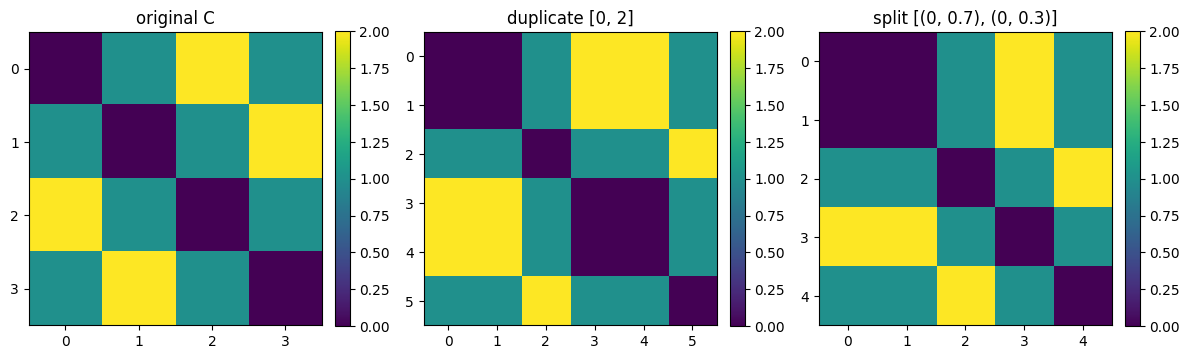

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, mat, title in [
    (axes[0], C, "original C"),
    (axes[1], C_dup, "duplicate [0, 2]"),
    (axes[2], C_sp, "split [(0, 0.7), (0, 0.3)]"),
]:
    im = ax.imshow(mat, cmap="viridis")
    ax.set_title(title)
    ax.set_xticks(range(mat.shape[0]))
    ax.set_yticks(range(mat.shape[0]))
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()

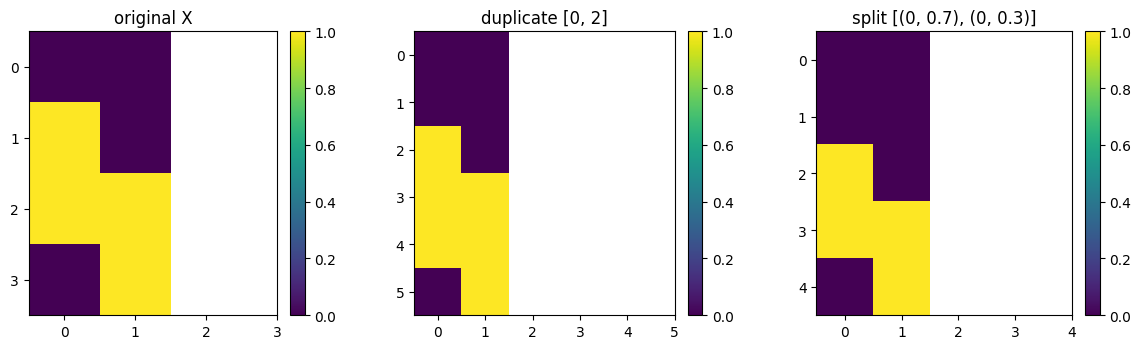

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, mat, title in [
    (axes[0], X, "original X"),
    (axes[1], X_dup, "duplicate [0, 2]"),
    (axes[2], X_sp, "split [(0, 0.7), (0, 0.3)]"),
]:
    im = ax.imshow(mat, cmap="viridis")
    ax.set_title(title)
    ax.set_xticks(range(mat.shape[0]))
    ax.set_yticks(range(mat.shape[0]))
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()